importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as ps
from six.moves import urllib
import warnings
import os

In [2]:
warnings.filterwarnings("ignore")

downoloading and importing dataset

In [3]:
download_dir="./data/"
os.makedirs(download_dir,exist_ok=True)

download_url="https://raw.githubusercontent.com/manishkr1754/CarDekho_Used_Car_Price_Prediction/main/notebooks/data/cardekho_dataset.csv"

file_name=os.path.basename(download_url)
download_path=os.path.join(download_dir,file_name)
urllib.request.urlretrieve(download_url,download_path)

print("DATA WITH NAME "+ file_name + " IS DOWNLOADED")


DATA WITH NAME cardekho_dataset.csv IS DOWNLOADED


In [4]:
df=pd.read_csv(download_path,index_col=[0])
df.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [5]:
print("dataset size:",df.shape)

dataset size: (15411, 13)


In [6]:
print("information of the dataset:")
print(df.info())

information of the dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 15411 entries, 0 to 19543
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15411 non-null  object 
 1   brand              15411 non-null  object 
 2   model              15411 non-null  object 
 3   vehicle_age        15411 non-null  int64  
 4   km_driven          15411 non-null  int64  
 5   seller_type        15411 non-null  object 
 6   fuel_type          15411 non-null  object 
 7   transmission_type  15411 non-null  object 
 8   mileage            15411 non-null  float64
 9   engine             15411 non-null  int64  
 10  max_power          15411 non-null  float64
 11  seats              15411 non-null  int64  
 12  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.6+ MB
None


taking numerical features and categorical features

In [7]:
numerical_features=[f for f in df.columns if df[f].dtype!='object']
categorical_features=[f for f in df.columns if df[f].dtype=='object']

print(f"{len(numerical_features)} numerical features:{numerical_features}")
print(f"{len(categorical_features)} categorical features:{categorical_features}")

7 numerical features:['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']
6 categorical features:['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']


identifying missing values for inspection

In [8]:
print("missing values:")

total=df.isnull().sum().sort_values(ascending=False) #total missing value
percent=(df.isnull().sum()/df.isnull().count()).sort_values(ascending=False) #avg missing value

pd.concat([total,percent],axis=1,keys=["total","percent"])

missing values:


,total,percent
car_name,0,0.0
brand,0,0.0
model,0,0.0
vehicle_age,0,0.0
km_driven,0,0.0
seller_type,0,0.0
fuel_type,0,0.0
transmission_type,0,0.0
mileage,0,0.0
engine,0,0.0


summary of the dataset

In [9]:
print("summary statistics:") #only for numerical features
df.describe()

summary statistics:


,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


finding unique category to check spelling, type error in categorical features

* nunique()- no.of. unique values
* unique() - unique values

In [10]:
print(f"{df['car_name'].unique()} - {df['car_name'].nunique()}")

['Maruti Alto' 'Hyundai Grand' 'Hyundai i20' 'Ford Ecosport'
 'Maruti Wagon R' 'Hyundai i10' 'Hyundai Venue' 'Maruti Swift'
 'Hyundai Verna' 'Renault Duster' 'Mini Cooper' 'Maruti Ciaz'
 'Mercedes-Benz C-Class' 'Toyota Innova' 'Maruti Baleno'
 'Maruti Swift Dzire' 'Volkswagen Vento' 'Hyundai Creta' 'Honda City'
 'Mahindra Bolero' 'Toyota Fortuner' 'Renault KWID' 'Honda Amaze'
 'Hyundai Santro' 'Mahindra XUV500' 'Mahindra KUV100' 'Maruti Ignis'
 'Datsun RediGO' 'Mahindra Scorpio' 'Mahindra Marazzo' 'Ford Aspire'
 'Ford Figo' 'Maruti Vitara' 'Tata Tiago' 'Volkswagen Polo' 'Kia Seltos'
 'Maruti Celerio' 'Datsun GO' 'BMW 5' 'Honda CR-V' 'Ford Endeavour'
 'Mahindra KUV' 'Honda Jazz' 'BMW 3' 'Audi A4' 'Tata Tigor'
 'Maruti Ertiga' 'Tata Safari' 'Mahindra Thar' 'Tata Hexa'
 'Land Rover Rover' 'Maruti Eeco' 'Audi A6' 'Mercedes-Benz E-Class'
 'Audi Q7' 'BMW Z4' 'BMW 6' 'Jaguar XF' 'BMW X5' 'MG Hector' 'Honda Civic'
 'Isuzu D-Max' 'Porsche Cayenne' 'BMW X1' 'Skoda Rapid' 'Ford Freestyle'
 'Skoda

In [11]:
print(f"{df['brand'].unique()} - {df['brand'].nunique()}")

['Maruti' 'Hyundai' 'Ford' 'Renault' 'Mini' 'Mercedes-Benz' 'Toyota'
 'Volkswagen' 'Honda' 'Mahindra' 'Datsun' 'Tata' 'Kia' 'BMW' 'Audi'
 'Land Rover' 'Jaguar' 'MG' 'Isuzu' 'Porsche' 'Skoda' 'Volvo' 'Lexus'
 'Jeep' 'Maserati' 'Bentley' 'Nissan' 'ISUZU' 'Ferrari' 'Mercedes-AMG'
 'Rolls-Royce' 'Force'] - 32


In [12]:
print(f"{df['model'].unique()} - {df['model'].nunique()}")

['Alto' 'Grand' 'i20' 'Ecosport' 'Wagon R' 'i10' 'Venue' 'Swift' 'Verna'
 'Duster' 'Cooper' 'Ciaz' 'C-Class' 'Innova' 'Baleno' 'Swift Dzire'
 'Vento' 'Creta' 'City' 'Bolero' 'Fortuner' 'KWID' 'Amaze' 'Santro'
 'XUV500' 'KUV100' 'Ignis' 'RediGO' 'Scorpio' 'Marazzo' 'Aspire' 'Figo'
 'Vitara' 'Tiago' 'Polo' 'Seltos' 'Celerio' 'GO' '5' 'CR-V' 'Endeavour'
 'KUV' 'Jazz' '3' 'A4' 'Tigor' 'Ertiga' 'Safari' 'Thar' 'Hexa' 'Rover'
 'Eeco' 'A6' 'E-Class' 'Q7' 'Z4' '6' 'XF' 'X5' 'Hector' 'Civic' 'D-Max'
 'Cayenne' 'X1' 'Rapid' 'Freestyle' 'Superb' 'Nexon' 'XUV300' 'Dzire VXI'
 'S90' 'WR-V' 'XL6' 'Triber' 'ES' 'Wrangler' 'Camry' 'Elantra' 'Yaris'
 'GL-Class' '7' 'S-Presso' 'Dzire LXI' 'Aura' 'XC' 'Ghibli' 'Continental'
 'CR' 'Kicks' 'S-Class' 'Tucson' 'Harrier' 'X3' 'Octavia' 'Compass' 'CLS'
 'redi-GO' 'Glanza' 'Macan' 'X4' 'Dzire ZXI' 'XC90' 'F-PACE' 'A8' 'MUX'
 'GTC4Lusso' 'GLS' 'X-Trail' 'XE' 'XC60' 'Panamera' 'Alturas' 'Altroz'
 'NX' 'Carnival' 'C' 'RX' 'Ghost' 'Quattroporte' 'Gurkha'] - 120


In [13]:
print(f"{df['seller_type'].unique()} - {df['seller_type'].nunique()}")

['Individual' 'Dealer' 'Trustmark Dealer'] - 3


In [14]:
print(f"{df['fuel_type'].unique()} - {df['fuel_type'].nunique()}")

['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric'] - 5


In [15]:
print(f"{df['transmission_type'].unique()} - {df['transmission_type'].nunique()}")

['Manual' 'Automatic'] - 2


percentage of each caqtegory in categorical data

In [16]:
for col in categorical_features:
  print(df[col].value_counts(normalize=True))
  print("-"*50)

car_name
Hyundai i20              0.058789
Maruti Swift Dzire       0.057751
Maruti Swift             0.050678
Maruti Alto              0.050483
Honda City               0.049121
                           ...   
Mercedes-AMG C           0.000065
Rolls-Royce Ghost        0.000065
Maserati Quattroporte    0.000065
Isuzu MUX                0.000065
Force Gurkha             0.000065
Name: proportion, Length: 121, dtype: float64
--------------------------------------------------
brand
Maruti           0.323924
Hyundai          0.193498
Honda            0.096360
Mahindra         0.065602
Toyota           0.051457
Ford             0.051262
Volkswagen       0.040231
Renault          0.034780
BMW              0.028486
Tata             0.027902
Mercedes-Benz    0.021867
Skoda            0.021673
Audi             0.012459
Datsun           0.011031
Jaguar           0.003828
Land Rover       0.003309
Jeep             0.002660
Kia              0.002076
Porsche          0.001363
Volvo            0.0

##exploratory data analysis

univariate analysis

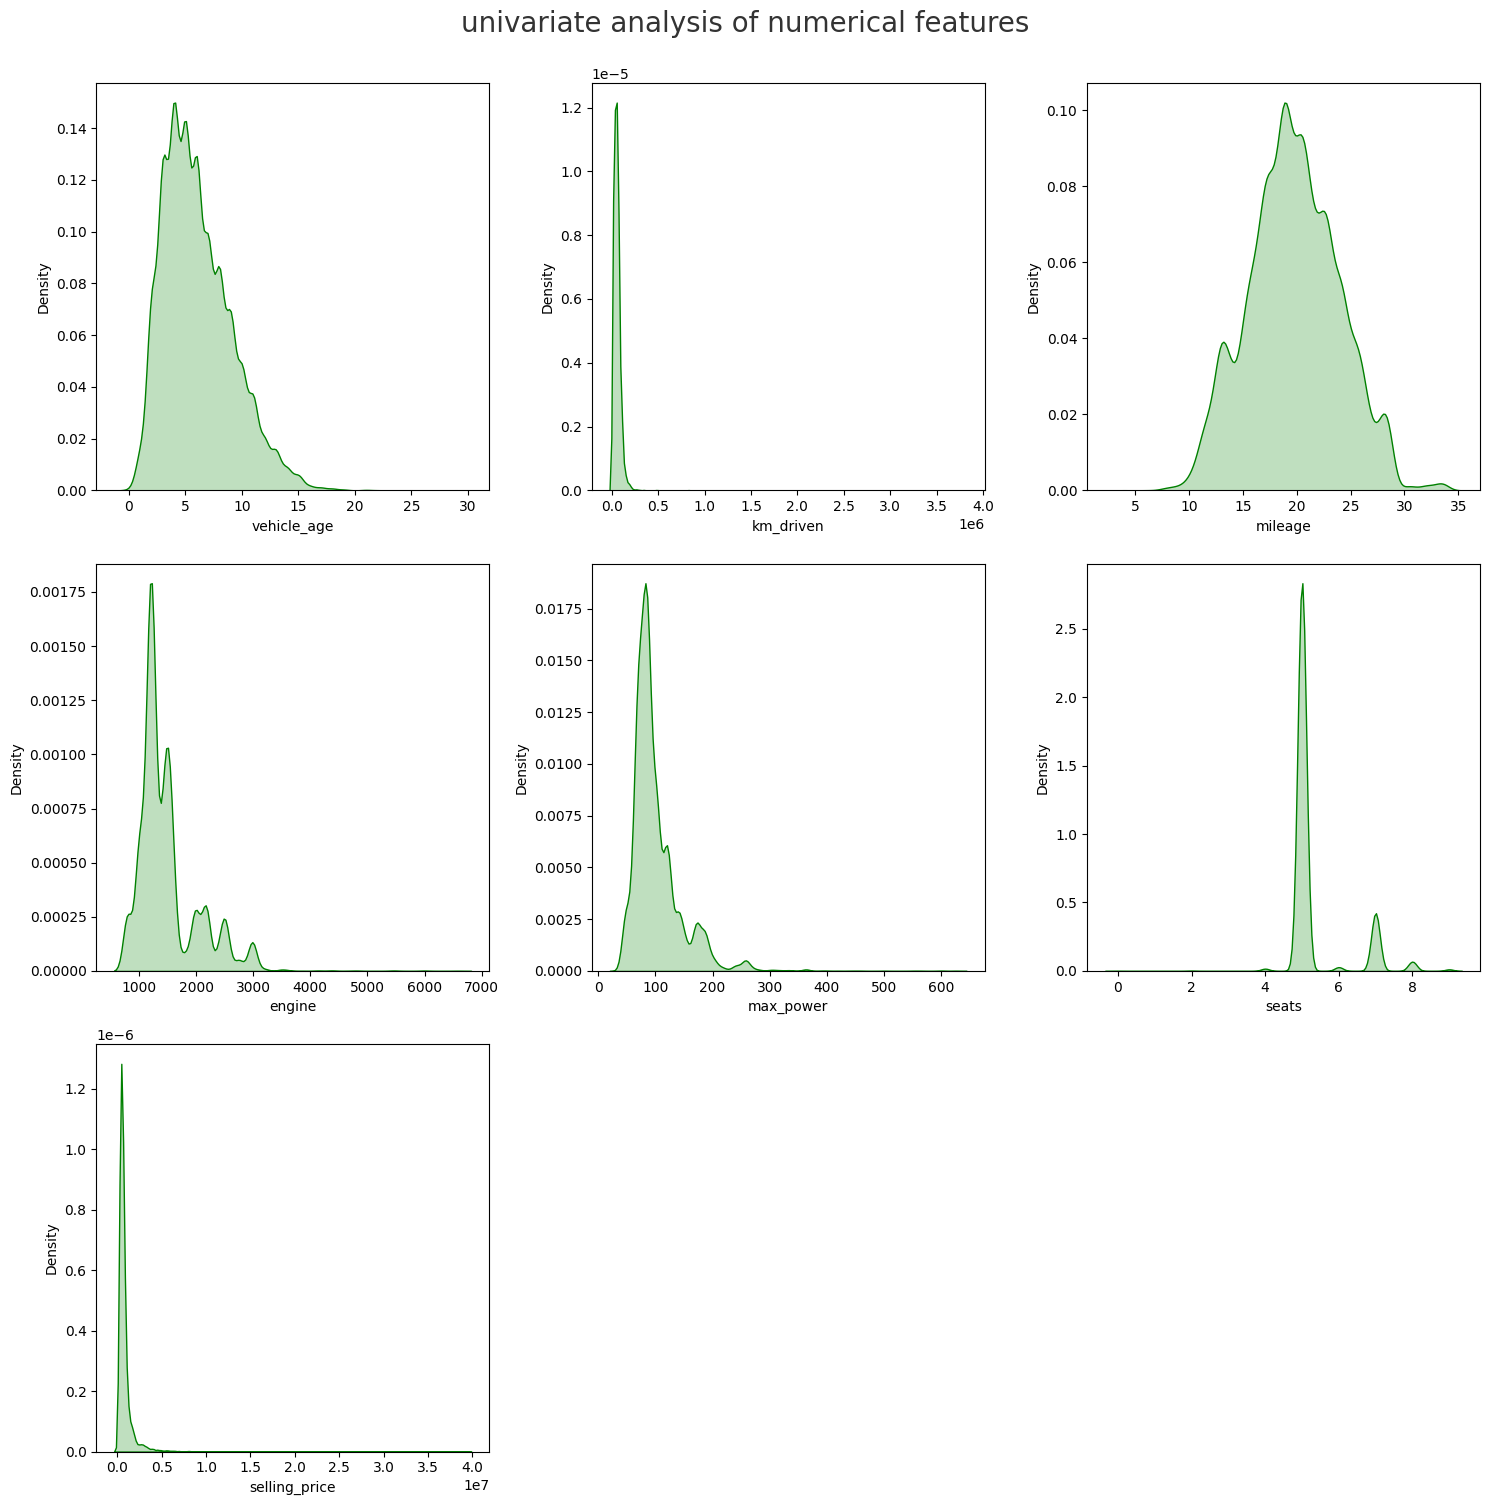

In [17]:
plt.figure(figsize=(15,15))
plt.suptitle("univariate analysis of numerical features",fontsize=20,alpha=0.8,y=1.0)

for i in range(0,len(numerical_features)):
  plt.subplot(3,3,i+1)
  sns.kdeplot(x=df[numerical_features[i]],shade=True,color='g')
  plt.xlabel(numerical_features[i])
  plt.tight_layout()
plt.show()

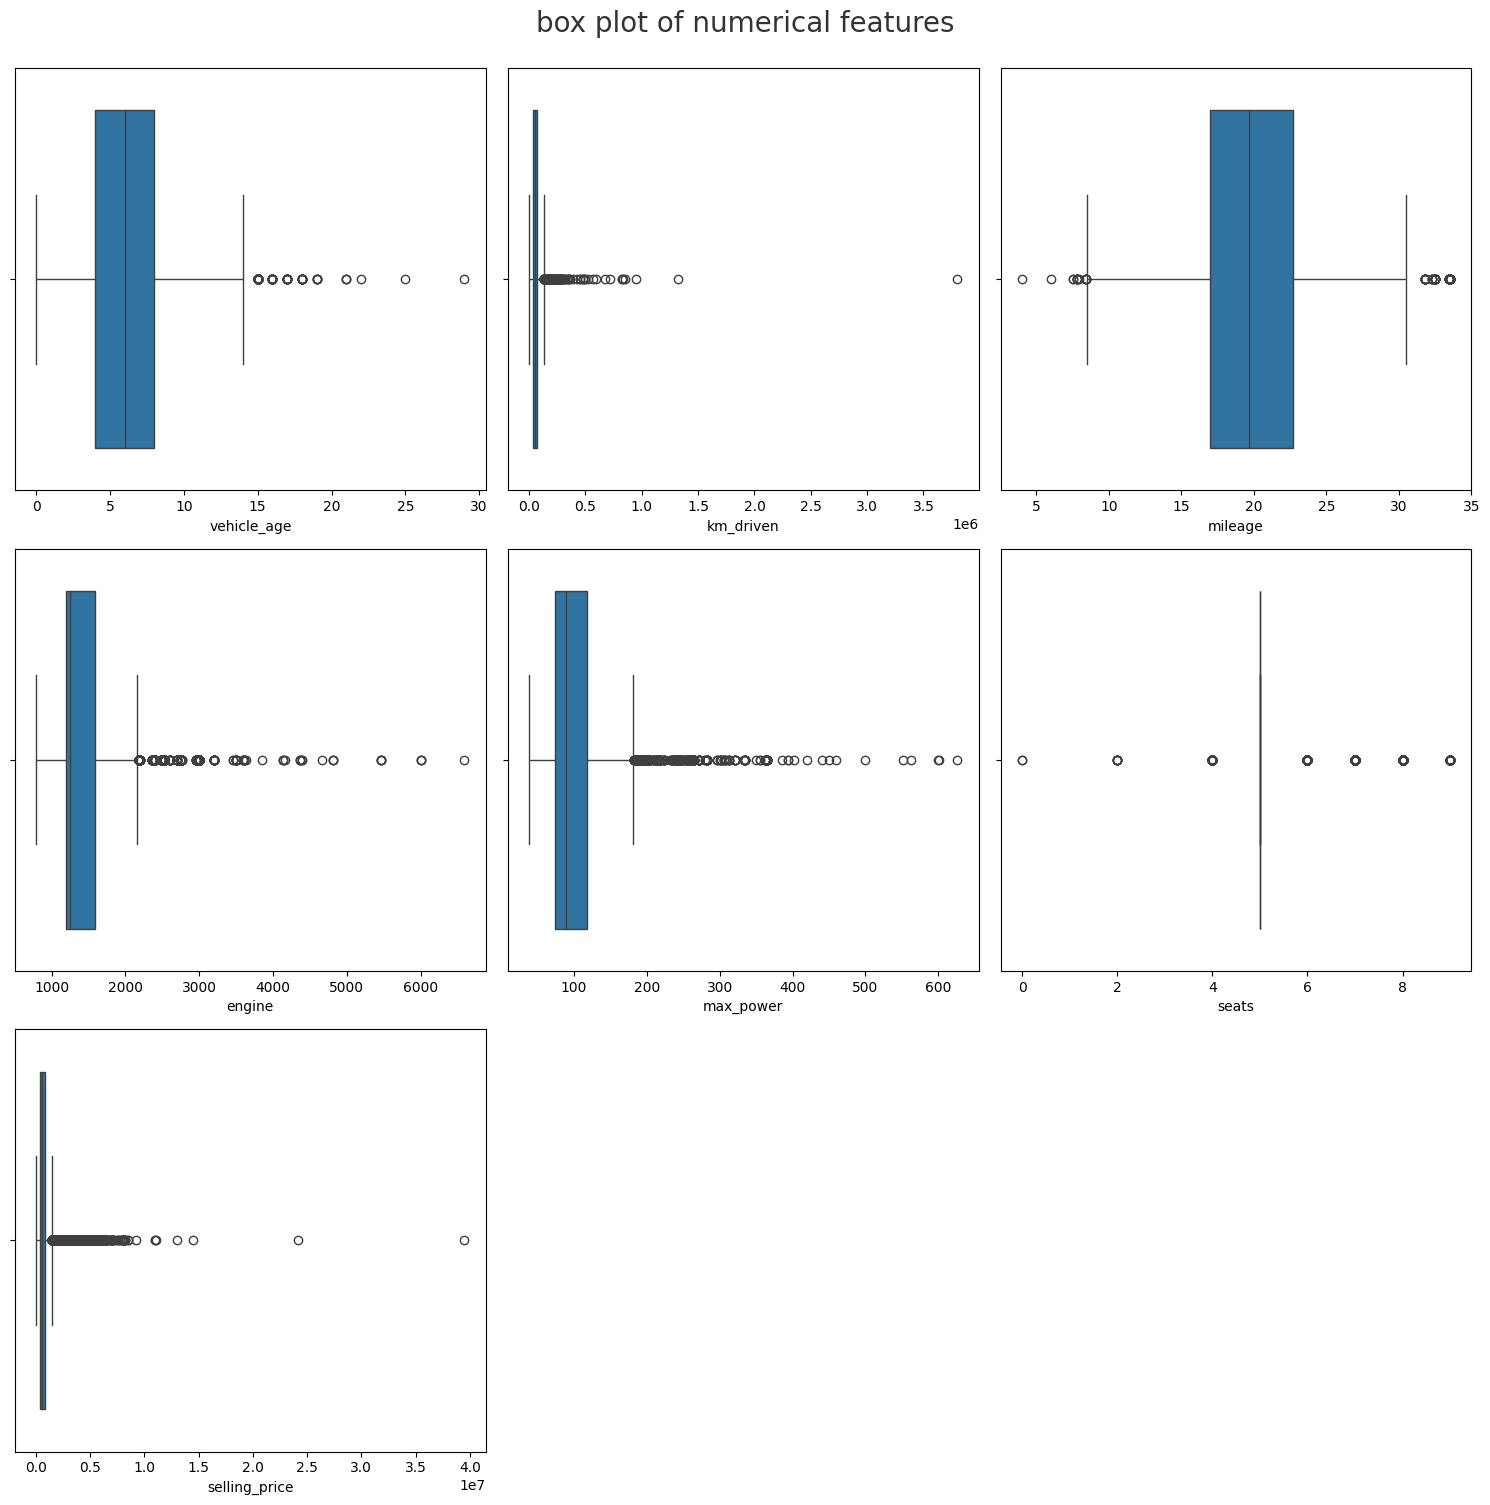

In [18]:
plt.figure(figsize=(15,15))
plt.suptitle("box plot of numerical features",fontsize=20,alpha=0.8,y=1.0)

for i in range(0,len(numerical_features)):
  plt.subplot(3,3,i+1)
  sns.boxplot(x=df[numerical_features[i]])
  plt.xlabel(numerical_features[i])
  plt.tight_layout()
plt.show()

bivariate analysis

In [19]:
continuous_features=[f for f in numerical_features if len(df[f].unique())>=10]
print("continuous features:",continuous_features)

continuous features: ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'selling_price']


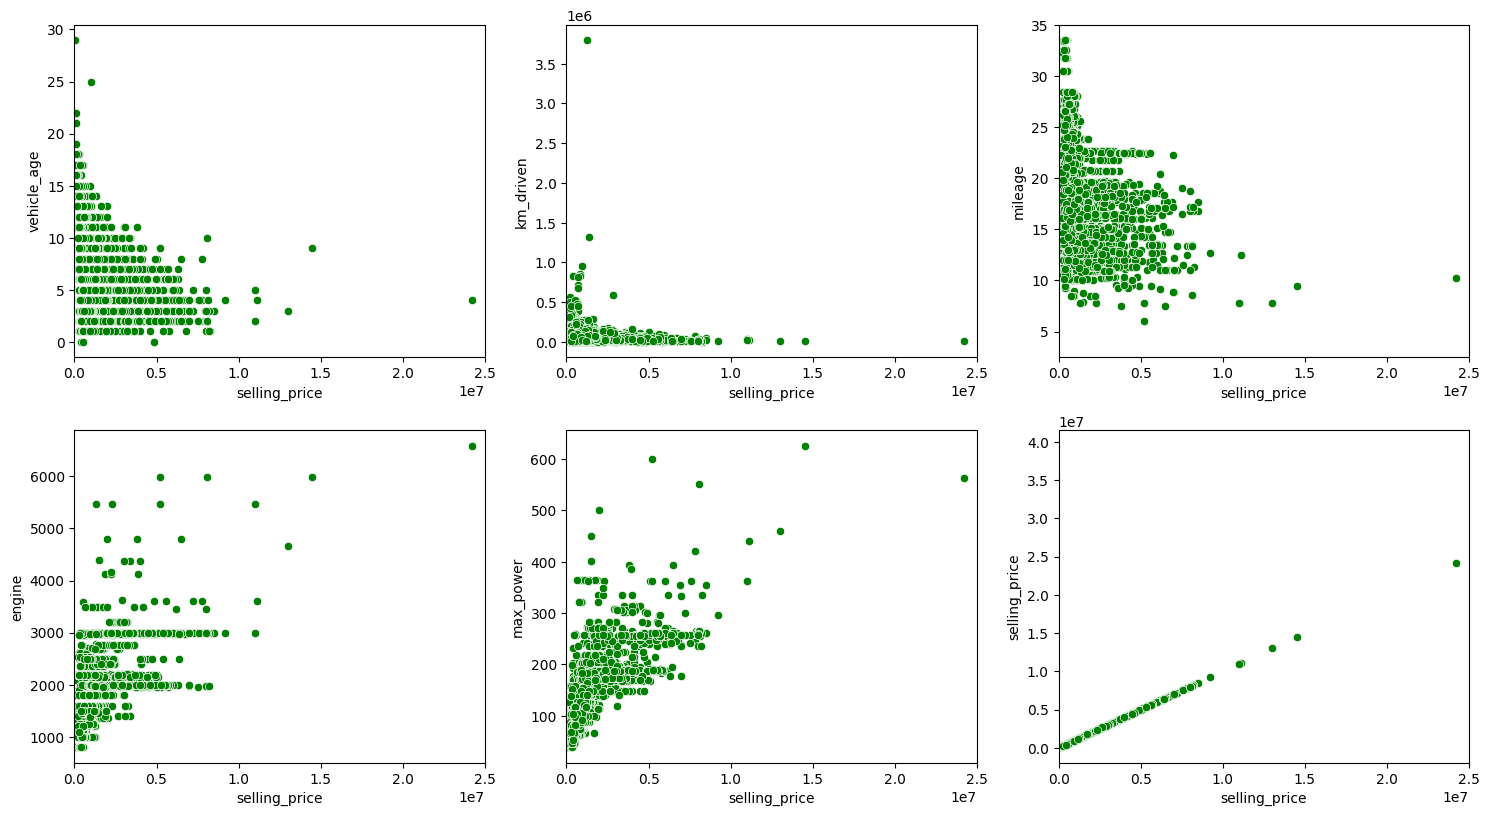

In [20]:
fig=plt.figure(figsize=(15,20))

for i in range(0,len(continuous_features)):
  plt.subplot(5,3,i+1)
  sns.scatterplot(data=df,y=df[continuous_features[i]],x="selling_price",color='g')
  plt.xlim(0,25000000)

  plt.tight_layout()
plt.show()

multivariate analysis

In [21]:
df[numerical_features].corr()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
vehicle_age,1.000000,0.333891,-0.257394,0.098965,0.005208,0.030791,-0.241851
km_driven,0.333891,1.000000,-0.105239,0.192885,0.044421,0.192830,-0.080030
mileage,-0.257394,-0.105239,1.000000,-0.632987,-0.533128,-0.440280,-0.305549
engine,0.098965,0.192885,-0.632987,1.000000,0.807368,0.551236,0.585844
max_power,0.005208,0.044421,-0.533128,0.807368,1.000000,0.172257,0.750236
seats,0.030791,0.192830,-0.440280,0.551236,0.172257,1.000000,0.115033
selling_price,-0.241851,-0.080030,-0.305549,0.585844,0.750236,0.115033,1.000000


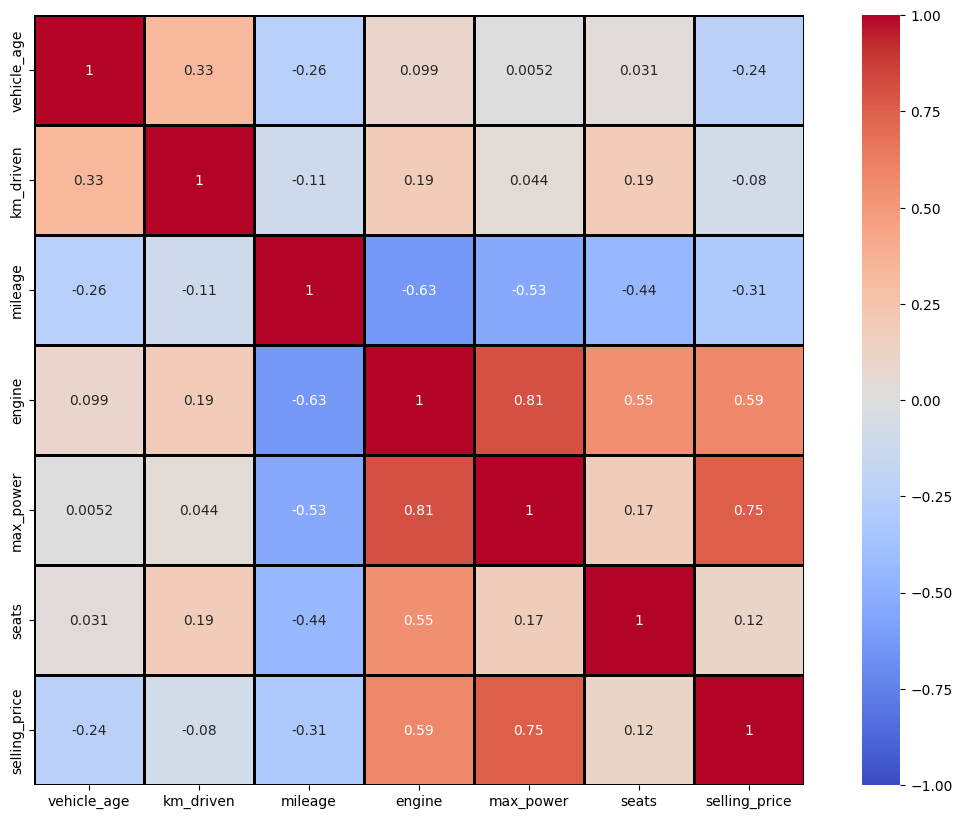

In [22]:
plt.figure(figsize=(15,10))
sns.heatmap(df[numerical_features].corr(),annot=True,cmap='coolwarm',vmin=-1,vmax=1,linecolor='black',linewidth=1,square=True)
plt.show()

multicollinearity for categorical features

In [23]:
from scipy.stats import chi2_contingency
chi2_test=[]

for f in categorical_features:
  if chi2_contingency(pd.crosstab(df[f],df['selling_price']))[1]<0.05:
    chi2_test.append('reject null hypothesis')
  else:
    chi2_test.append('fail to reject null hypothesis')

test_result=pd.DataFrame(data=[categorical_features,chi2_test]).T
test_result.columns=['categorical feature','hhypothesis result']
test_result

,categorical feature,hhypothesis result
0,car_name,reject null hypothesis
1,brand,reject null hypothesis
2,model,reject null hypothesis
3,seller_type,reject null hypothesis
4,fuel_type,reject null hypothesis
5,transmission_type,reject null hypothesis


**pd.crosstab()-** simple cross-tabulation (contingency table) of two or more categorical variables

##data visualization

1. selling price distribution (target feature distribution)

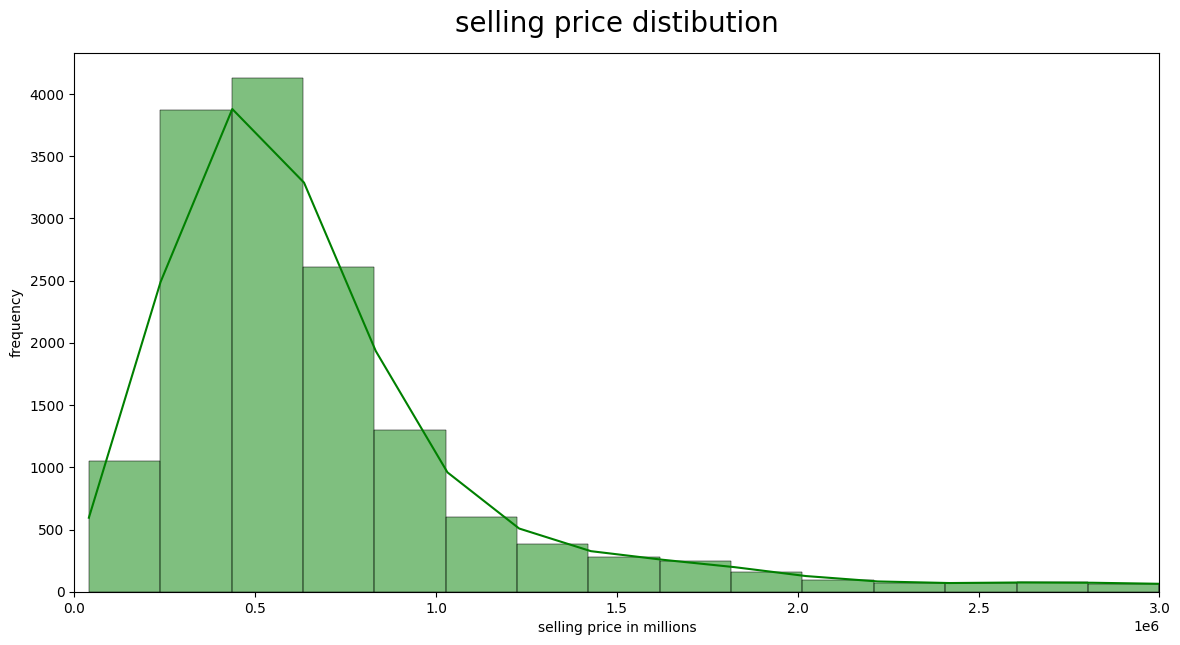

In [24]:
plt.subplots(figsize=(14,7))
sns.histplot(df.selling_price,bins=200,kde=True,color='g')
plt.title("selling price distibution",fontsize=20,pad=15)
plt.xlabel("selling price in millions")
plt.ylabel("frequency")
plt.xlim(0,3000000)
plt.show()

2. top 10 most sold cars in website

In [25]:
df.car_name.value_counts()[0:10]

,count
car_name,
Hyundai i20,906
Maruti Swift Dzire,890
Maruti Swift,781
Maruti Alto,778
Honda City,757
Maruti Wagon R,717
Hyundai Grand,580
Toyota Innova,545
Hyundai Verna,492


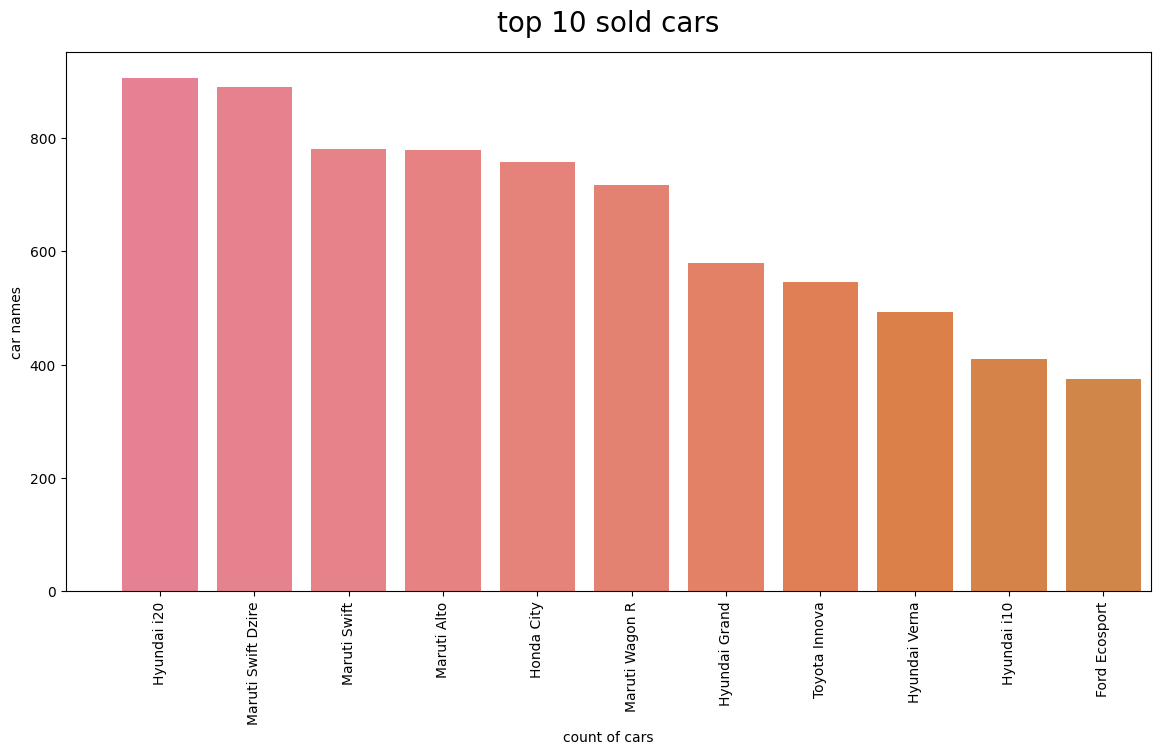

In [26]:
plt.subplots(figsize=(14,7))
sns.countplot(x='car_name',data=df,palette="husl",order=df['car_name'].value_counts().index)
plt.title("top 10 sold cars",fontsize=20,pad=15)
plt.xlabel("count of cars")
plt.ylabel("car names")
plt.xticks(rotation=90)
plt.xlim(-1,10.5)
plt.show()

In [27]:
print("checking the hyundai i20 mean price:")
hyundai_i20=df[df['car_name']=='Hyundai i20']['selling_price'].mean()
print(f"{hyundai_i20:.2f}")

checking the hyundai i20 mean price:
543603.75


3. most sold car brand

In [28]:
df.brand.value_counts()[0:10]

,count
brand,
Maruti,4992
Hyundai,2982
Honda,1485
Mahindra,1011
Toyota,793
Ford,790
Volkswagen,620
Renault,536
BMW,439


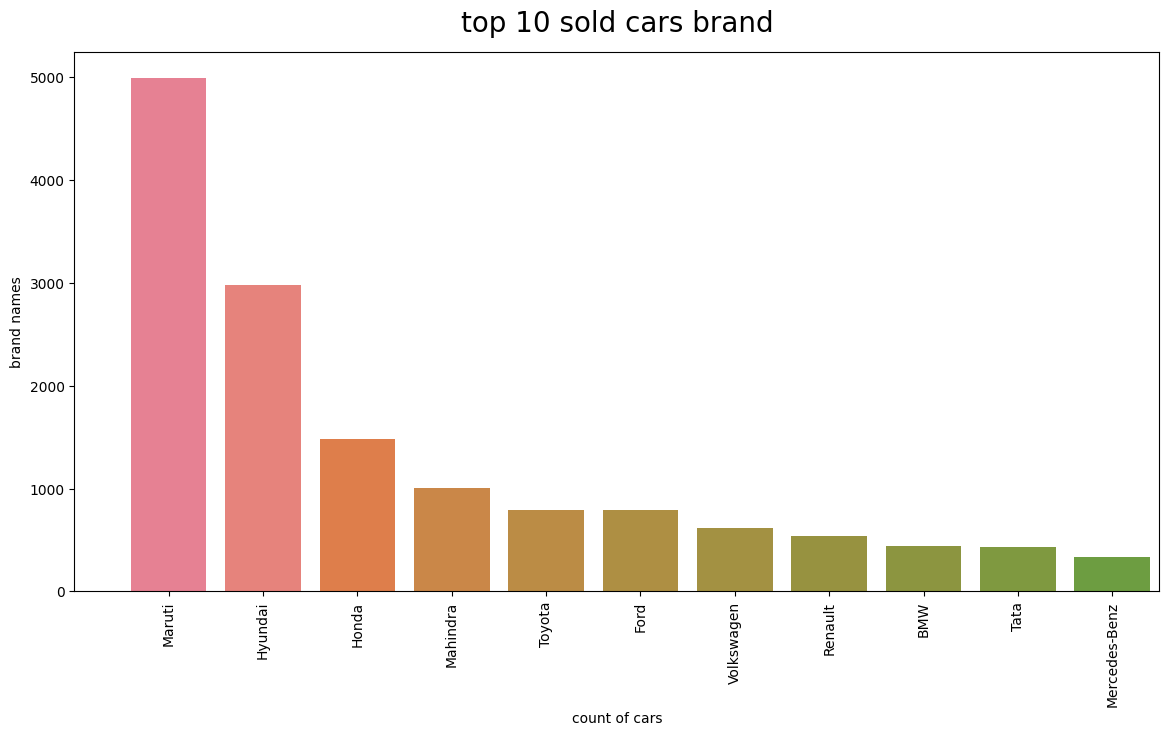

In [29]:
plt.subplots(figsize=(14,7))
sns.countplot(x='brand',data=df,palette="husl",order=df['brand'].value_counts().index)
plt.title("top 10 sold cars brand",fontsize=20,pad=15)
plt.xlabel("count of cars")
plt.ylabel("brand names")
plt.xticks(rotation=90)
plt.xlim(-1,10.5)
plt.show()

In [30]:
print("checking the maruti brand mean price:")
maruti=df[df['brand']=='Maruti']['selling_price'].mean()
print(f"{maruti:.2f}")

checking the maruti brand mean price:
487089.32


4. most mileage car

In [31]:
milaeage_car=df.groupby('car_name')['mileage'].mean().sort_values(ascending=False).head(10)
milaeage_car

,mileage
car_name,
Tata Tiago,24.625103
Maruti Ciaz,24.289046
Maruti Vitara,24.231932
Renault KWID,24.037810
Maruti Celerio,23.703502
Maruti Dzire VXI,23.512941
Maruti Dzire ZXI,23.260000
Maruti Dzire LXI,23.260000
Ford Aspire,22.993846


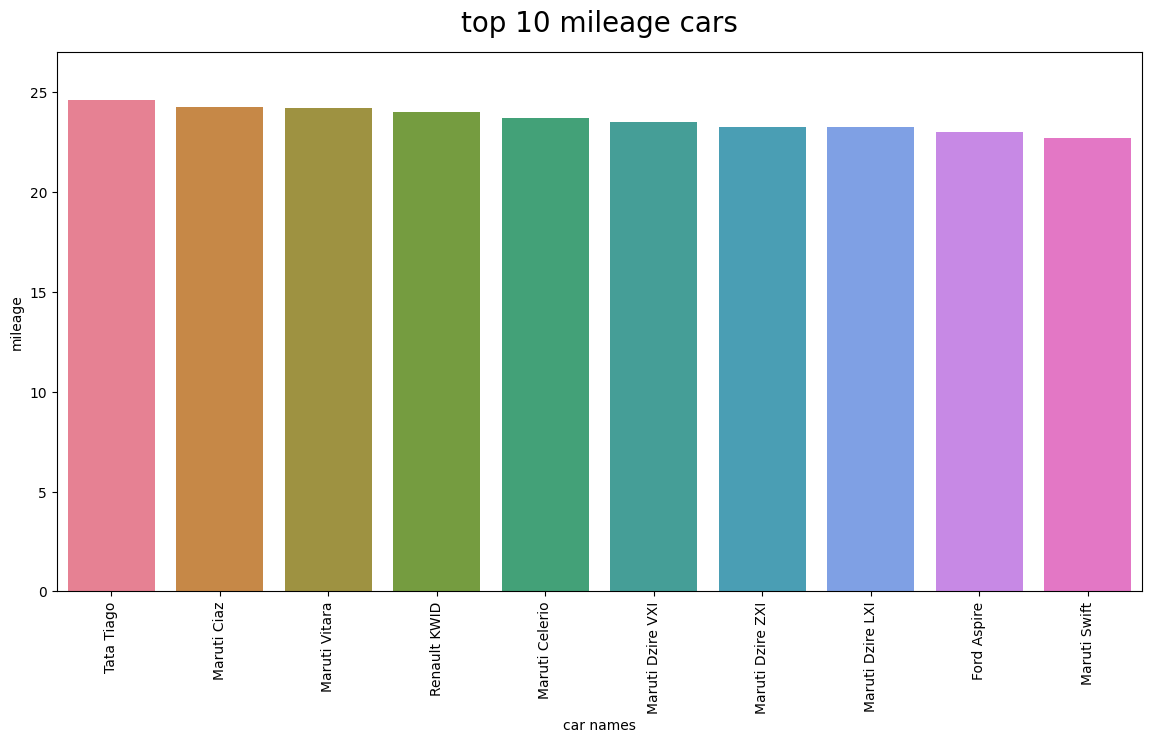

In [32]:
plt.subplots(figsize=(14,7))
sns.barplot(x=milaeage_car.index,y=milaeage_car.values,palette="husl")
plt.title("top 10 mileage cars",fontsize=20,pad=15)
plt.xlabel("car names")
plt.ylabel("mileage")
plt.ylim(0,27)
plt.xticks(rotation=90)
plt.show()

5. kilometers driven vs selling price

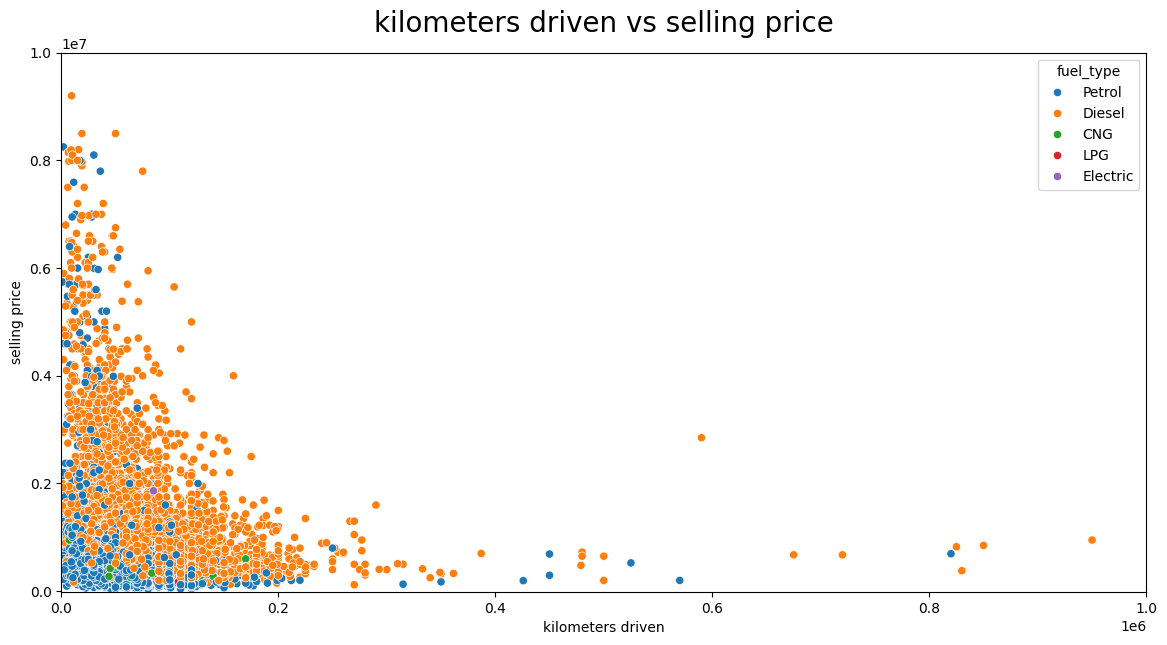

In [33]:
plt.subplots(figsize=(14,7))
sns.scatterplot(data=df,y='selling_price',x='km_driven',hue='fuel_type')
plt.title("kilometers driven vs selling price",fontsize=20,pad=15)
plt.xlabel("kilometers driven")
plt.ylabel("selling price")
plt.xlim(0,1000000)
plt.ylim(-10000,10000000)
plt.show()

6. fuel type and selling price

In [34]:
fuel=df.groupby('fuel_type')['selling_price'].median().sort_values(ascending=False)
fuel

,selling_price
fuel_type,
Electric,1857500.0
Diesel,700000.0
Petrol,460000.0
CNG,370000.0
LPG,182500.0


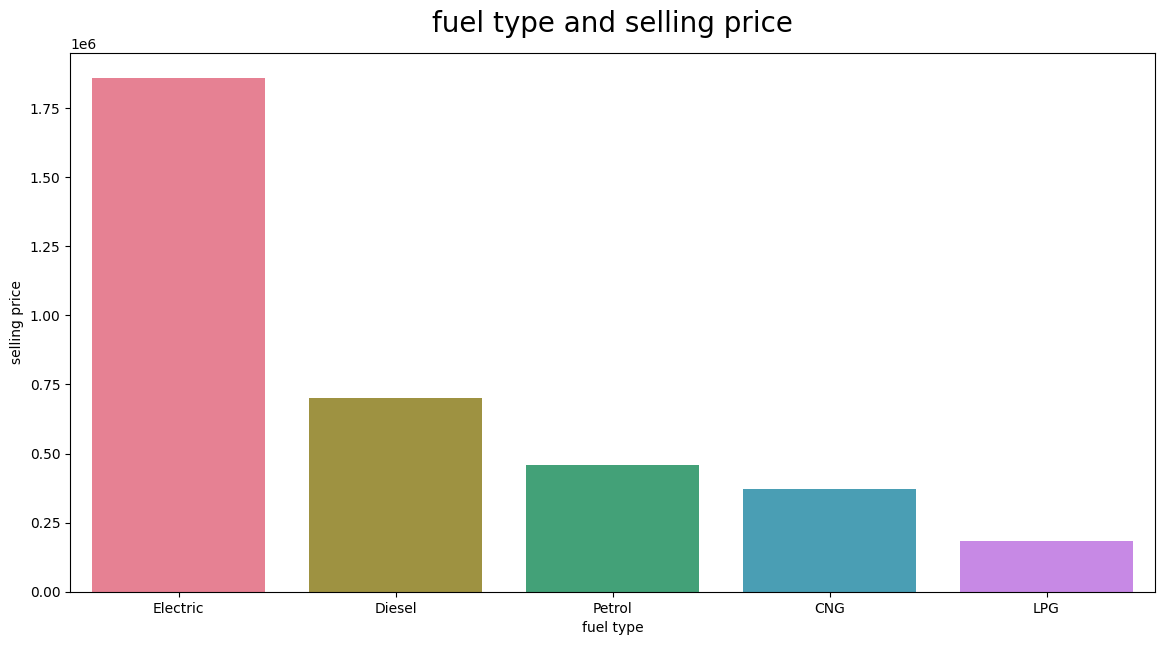

In [35]:
plt.subplots(figsize=(14,7))
sns.barplot(x=fuel.index,y=fuel.values,palette="husl")
plt.title("fuel type and selling price",fontsize=20,pad=15)
plt.xlabel("fuel type")
plt.ylabel("selling price")
plt.show()

6. fuel type vs mileage

In [36]:
fuel_mileage=df.groupby('fuel_type')['mileage'].mean().sort_values(ascending=False)
fuel_mileage

,mileage
fuel_type,
CNG,25.814651
Diesel,20.060030
Electric,19.160000
Petrol,19.123045
LPG,17.836364


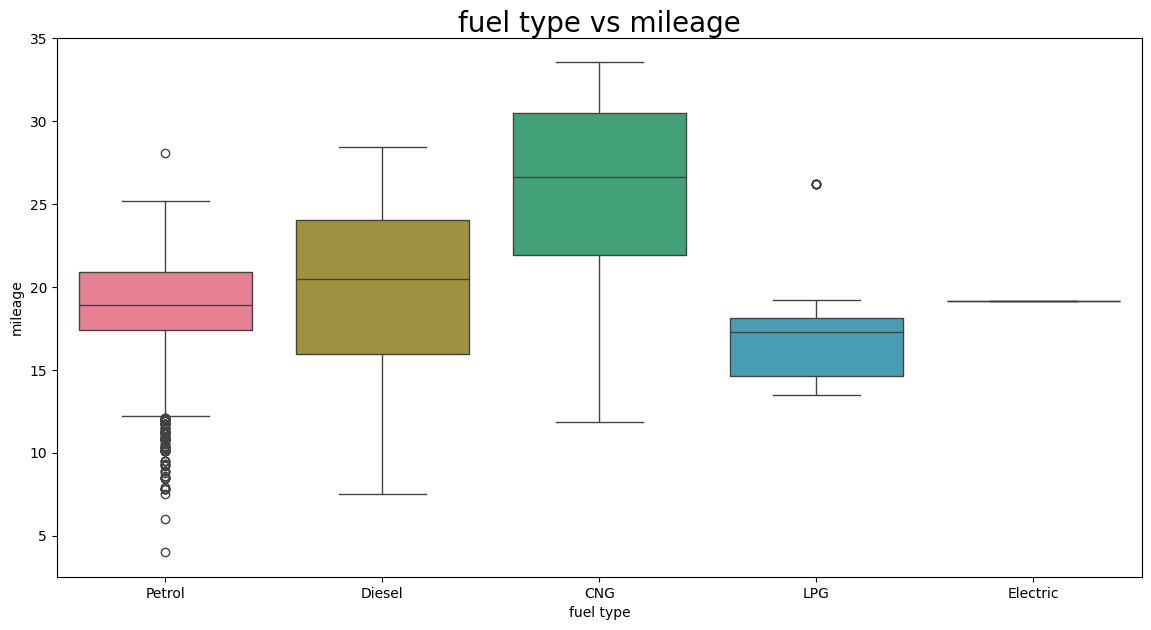

In [37]:
plt.subplots(figsize=(14,7))
sns.boxplot(x='fuel_type',y='mileage',palette="husl",data=df)
plt.title("fuel type vs mileage",fontsize=20,pad=1)
plt.ylabel("mileage")
plt.xlabel("fuel type")
plt.show()

7. milleage vs selling price

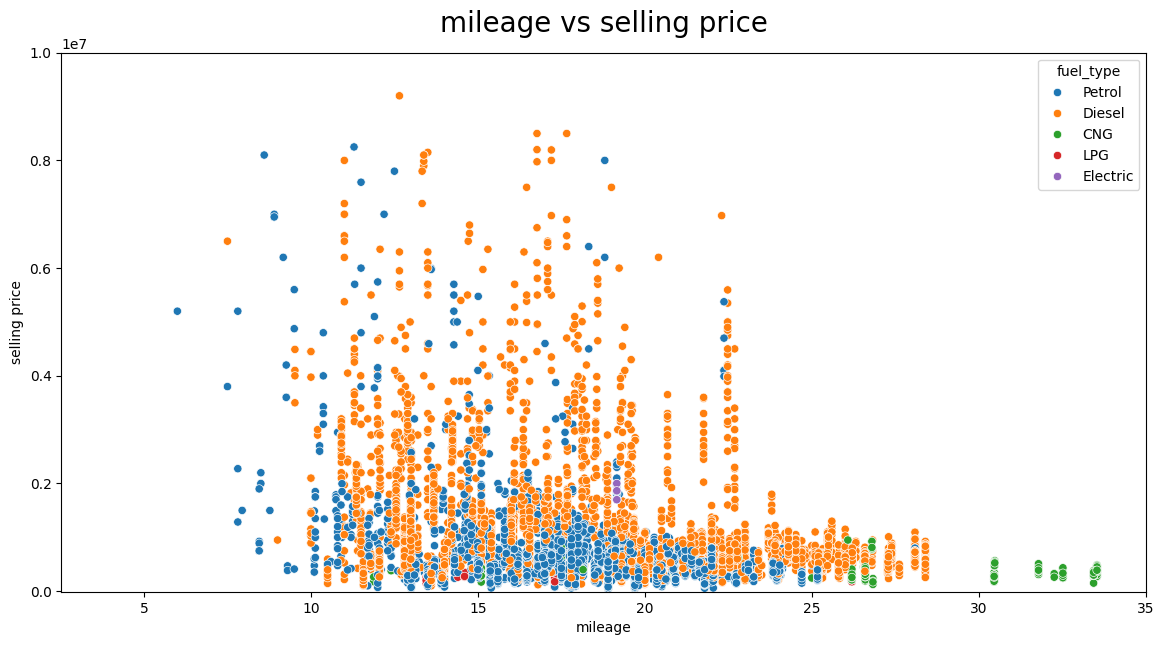

In [38]:
plt.subplots(figsize=(14,7))
sns.scatterplot(data=df,y='selling_price',x='mileage',hue='fuel_type')
plt.title("mileage vs selling price",fontsize=20,pad=15)
plt.xlabel("mileage")
plt.ylabel("selling price")
plt.ylim(-10000,10000000)
plt.show()

8. mileage distribution

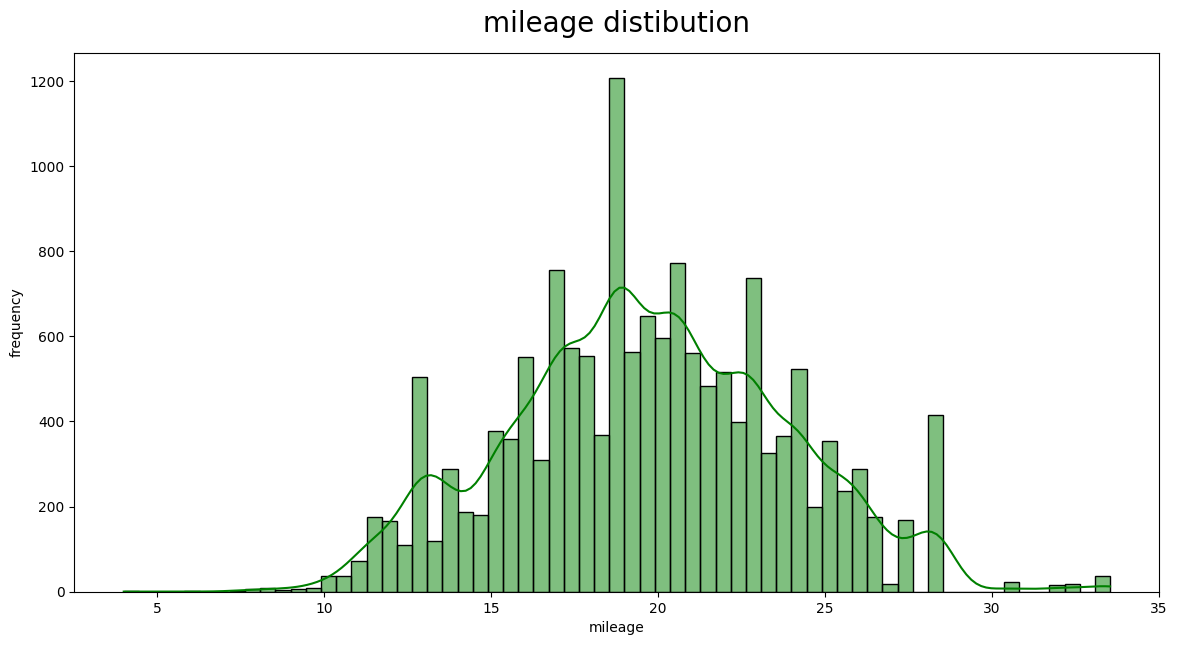

In [39]:
plt.subplots(figsize=(14,7))
sns.histplot(x=df.mileage,kde=True,color='g')
plt.title("mileage distibution",fontsize=20,pad=15)
plt.xlabel("mileage")
plt.ylabel("frequency")
plt.show()

9. vehicle age vs selling price


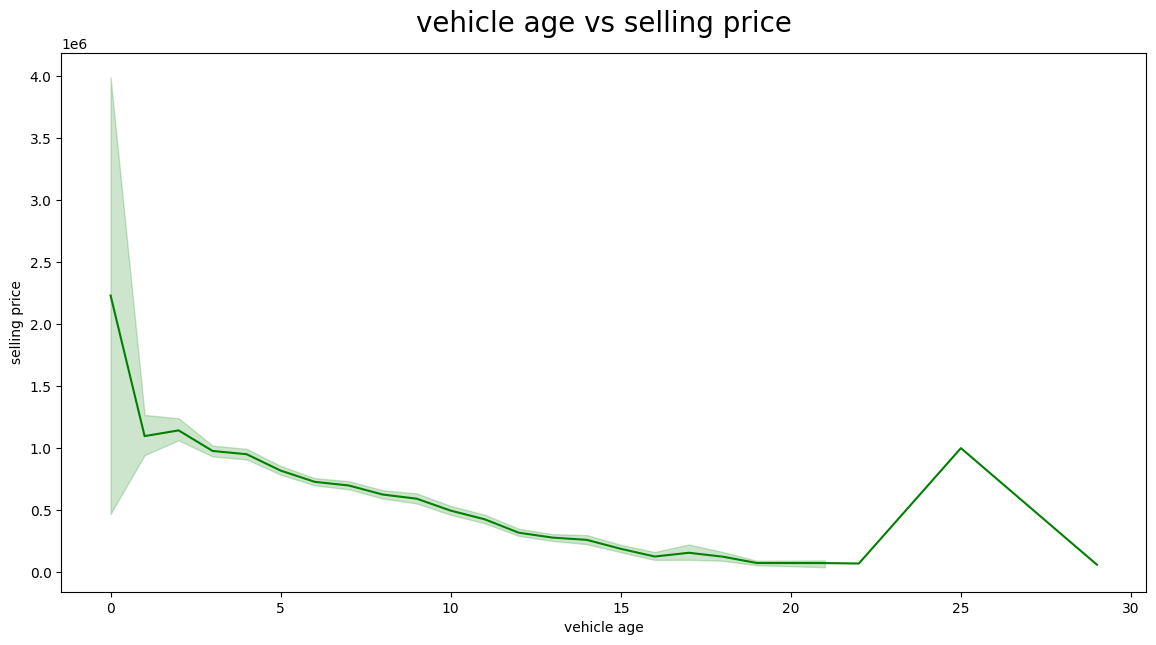

In [40]:
plt.subplots(figsize=(14,7))
sns.lineplot(data=df,y='selling_price',x='vehicle_age',color='g')
plt.title("vehicle age vs selling price",fontsize=20,pad=15)
plt.xlabel("vehicle age")
plt.ylabel("selling price")
plt.show()

10. vehicle age vs mileage

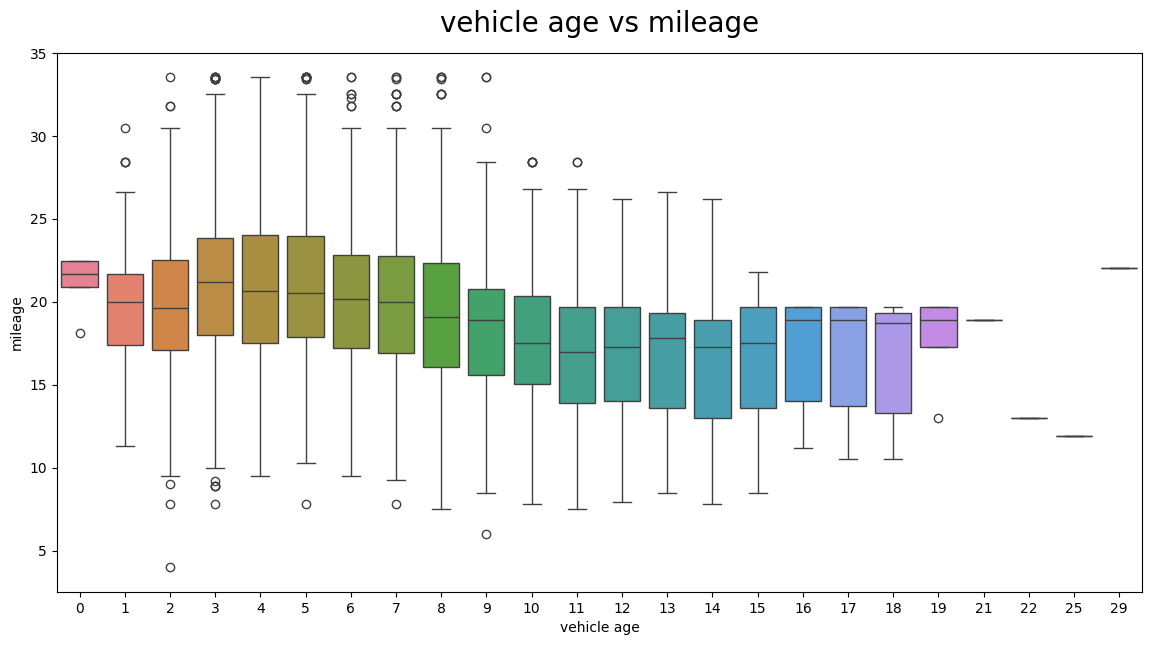

In [41]:
plt.subplots(figsize=(14,7))
sns.boxplot(data=df,y='mileage',x='vehicle_age',palette='husl')
plt.title("vehicle age vs mileage",fontsize=20,pad=15)
plt.xlabel("vehicle age")
plt.ylabel("mileage")
plt.show()

In [42]:
oldest_car=df.groupby('car_name')['vehicle_age'].max().sort_values(ascending=False).head(10)
oldest_car

,vehicle_age
car_name,
Maruti Alto,29
BMW 3,25
Honda City,22
Maruti Wagon R,21
Mahindra Scorpio,18
Mahindra Bolero,18
Skoda Octavia,18
Mercedes-Benz E-Class,17
Honda CR-V,17


11. transmission type vs count

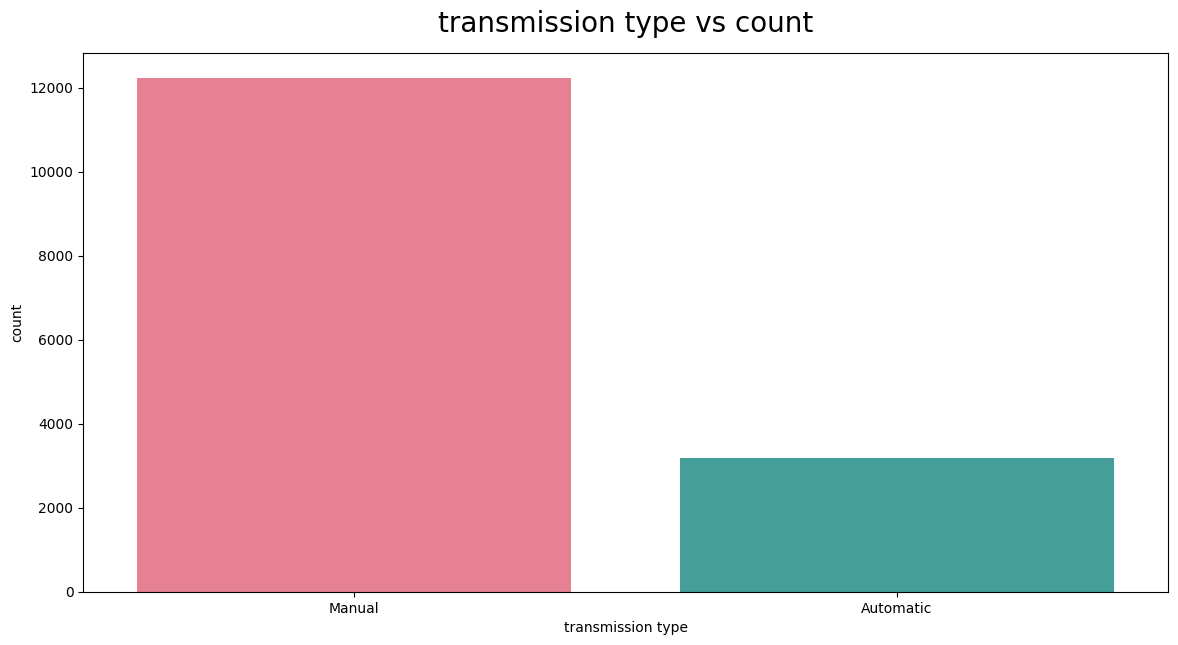

In [43]:
plt.subplots(figsize=(14,7))
sns.countplot(x='transmission_type',data=df,palette="husl")
plt.title("transmission type vs count",fontsize=20,pad=15)
plt.xlabel("transmission type")
plt.ylabel("count")
plt.show()

12. seller type vs selling price

In [44]:
dealer=df.groupby('seller_type')['selling_price'].median().sort_values(ascending=False)
dealer

,selling_price
seller_type,
Dealer,591000.0
Trustmark Dealer,540000.0
Individual,507000.0


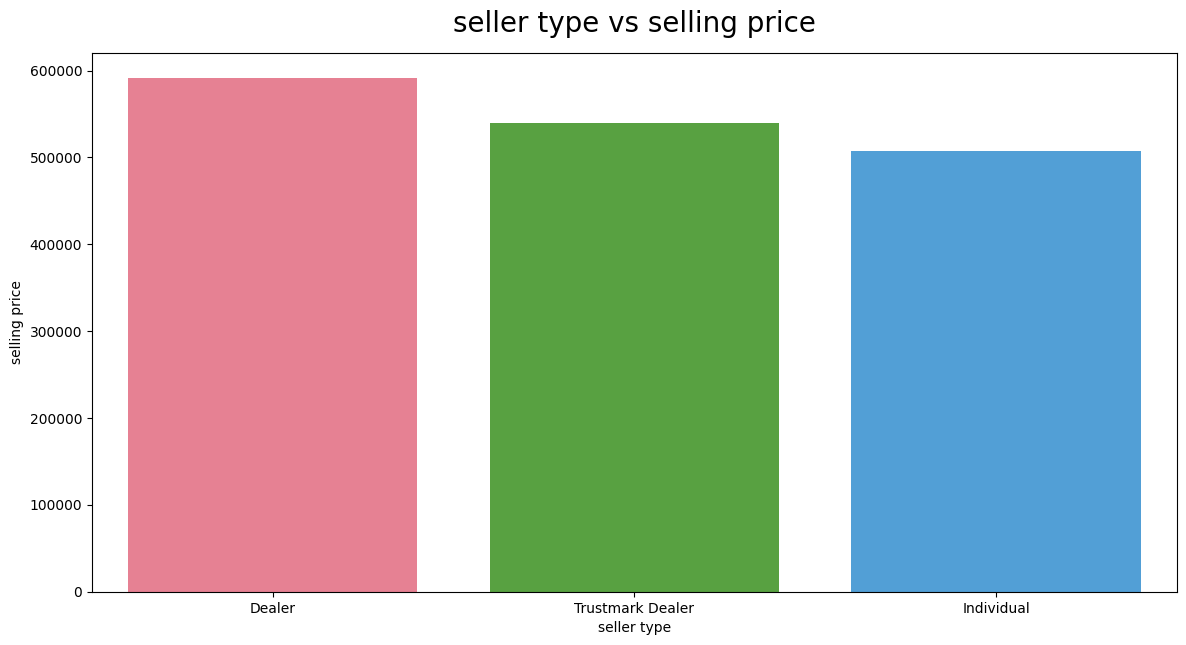

In [45]:
plt.subplots(figsize=(14,7))
sns.barplot(x=dealer.index,y=dealer.values,palette="husl")
plt.title("seller type vs selling price",fontsize=20,pad=15)
plt.xlabel("seller type")
plt.ylabel("selling price")
plt.show()

##feature engineering

In [46]:
df.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


### removing unwanted features

original dataset

In [47]:
df_model=df.copy() #to prevent making changes in original
df_model.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [48]:
df_model.drop(labels=['car_name','brand','model'],axis=1,inplace=True)
df_model.head()

,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


converting categorical columns in numerical using one hot encoding

In [49]:
df_model=pd.get_dummies(df_model,dtype=float)
df_model

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,9,120000,19.70,796,46.30,5,120000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,5,20000,18.90,1197,82.00,5,550000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,11,60000,17.00,1197,80.00,5,215000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,9,37000,20.92,998,67.10,5,226000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,6,30000,22.77,1498,98.59,5,570000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19537,9,10723,19.81,1086,68.05,5,250000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19540,2,18000,17.50,1373,91.10,7,925000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19541,6,67000,21.14,1498,103.52,5,425000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
19542,5,3800000,16.00,2179,140.00,7,1225000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [50]:
df_model.dtypes

,0
vehicle_age,int64
km_driven,int64
mileage,float64
engine,int64
max_power,float64
seats,int64
selling_price,int64
seller_type_Dealer,float64
seller_type_Individual,float64
seller_type_Trustmark Dealer,float64


creating feature matrix

In [51]:
X=df_model.drop(labels=['selling_price'],axis=1) #independent variables
Y=df_model['selling_price'] #dependent variable

In [52]:
X   #except selling_price other columns are independent feature

,vehicle_age,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,9,120000,19.70,796,46.30,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1,5,20000,18.90,1197,82.00,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2,11,60000,17.00,1197,80.00,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,9,37000,20.92,998,67.10,5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
4,6,30000,22.77,1498,98.59,5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19537,9,10723,19.81,1086,68.05,5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19540,2,18000,17.50,1373,91.10,7,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
19541,6,67000,21.14,1498,103.52,5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
19542,5,3800000,16.00,2179,140.00,7,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [53]:
Y #selling_price alone is a dependent feature

,selling_price
0,120000
1,550000
2,215000
3,226000
4,570000
...,...
19537,250000
19540,925000
19541,425000
19542,1225000


finding important model features

In [54]:
from sklearn.ensemble import ExtraTreesRegressor
model=ExtraTreesRegressor()
model.fit(X,Y)

ExtraTreesRegressor()

In [55]:
print(model.feature_importances_)

[1.72827084e-01 4.82572744e-02 6.42121903e-02 1.15550106e-01
 4.03266398e-01 1.34294534e-02 4.77717346e-03 3.41411476e-03
 2.38667991e-05 5.27739192e-05 7.68023510e-03 4.38786349e-05
 2.56607170e-06 1.95969376e-02 6.39456587e-02 8.29202889e-02]


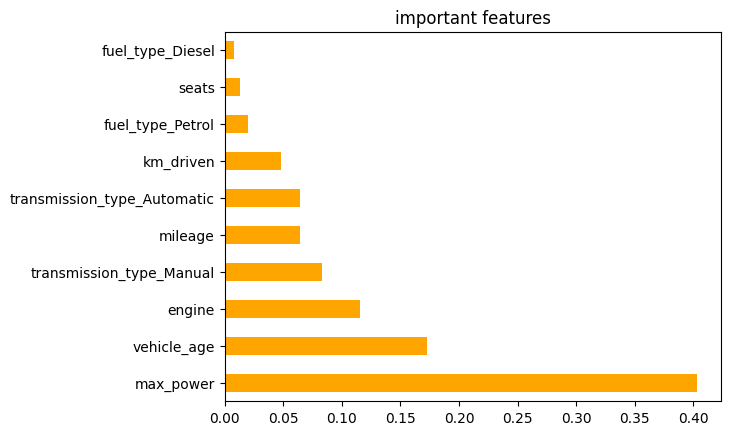

In [56]:
imp_feature=pd.Series(model.feature_importances_,index=X.columns)
imp_feature.nlargest(10).plot(kind='barh',color='orange')
plt.title('important features')
plt.show()

##model building

train-test split

In [57]:
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=3)

In [58]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,explained_variance_score,r2_score

In [59]:
models=[LinearRegression,Ridge,Lasso,SVR,DecisionTreeRegressor,ExtraTreesRegressor,RandomForestRegressor]
model_names=['LinearRegression','Ridge','Lasso','SVR','DecisionTreeRegressor','ExtraTreesRegressor','RandomForestRegressor']

mse=[]
rmse=[]
evs=[]
r_square_score=[]

for model in models:
  regressor=model()
  regressor.fit(X_train,Y_train)
  pred=regressor.predict(X_test)

  mse.append(mean_squared_error(y_true= Y_test, y_pred=pred))
  rmse.append(np.sqrt(mean_squared_error(y_true= Y_test, y_pred= pred)))
  evs.append(explained_variance_score(y_true= Y_test,y_pred= pred))
  r_square_score.append(r2_score(y_true= Y_test, y_pred= pred))


In [60]:
ML_model_df=pd.DataFrame({'model':model_names,
                          'mse':mse,
                          'rmse':rmse,
                          'evs':evs,
                          'r_square_score':r_square_score})
ML_model_df.set_index('model',inplace=True)
ML_model_df

,mse,rmse,evs,r_square_score
model,,,,
LinearRegression,2.185960e+11,467542.539990,0.685279,0.685090
Ridge,2.185927e+11,467538.986504,0.685284,0.685095
Lasso,2.185952e+11,467541.653847,0.685280,0.685091
SVR,7.409353e+11,860776.003232,0.000099,-0.067394
DecisionTreeRegressor,1.124939e+11,335401.048778,0.837956,0.837941
ExtraTreesRegressor,4.327650e+10,208030.044024,0.937666,0.937656
RandomForestRegressor,4.831674e+10,219810.689303,0.930426,0.930395


##selection of best model & hyper parameter tuning

In [61]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,r2_score,explained_variance_score
import numpy as np

In [62]:
param_grid={
    'n_estimators':[100,200,300,400,500],
    'max_features':['auto','sqrt','log2'],
    'max_depth':[None,10,20,30,40,50],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4],
    'bootstrap':[True,False]
}

In [63]:
#initailaizing random forest
rf=RandomForestRegressor()

#hyper parameter tuning
random_search=RandomizedSearchCV(estimator=rf,param_distributions=param_grid,n_iter=100,cv=3,verbose=2,random_state=42,n_jobs=-1)

#fitting model in training data
random_search.fit(X_train,Y_train)

#best hyper parameters
best_rf=random_search.best_estimator_

#make predictions
Y_pred=best_rf.predict(X_test)

#calculate evaluation metrics
mse_rf=mean_squared_error(Y_test,Y_pred)
rmse_rf=np.sqrt(mse_rf)
evs_rf=explained_variance_score(Y_test,Y_pred)
r2_score_rf=r2_score(Y_test,Y_pred)

mse.append(mse_rf)
rmse.append(rmse_rf)
evs.append(evs_rf)
r_square_score.append(r2_score_rf)

print("Evaluation Metrics for RandomForest")
print(f"best hyper parameters: {random_search.best_params_}")
print(f"mean squared error: {mse_rf}")
print(f"root mean squared error: {rmse_rf}")
print(f"explained variance score: {evs_rf}")
print(f"r2 score: {r2_score_rf}")


Fitting 3 folds for each of 100 candidates, totalling 300 fits
Evaluation Metrics for RandomForest
best hyper parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 40, 'bootstrap': False}
mean squared error: 45052962401.735275
root mean squared error: 212256.8312251346
explained variance score: 0.9351209378875087
r2 score: 0.935096573993532


## generating pickle file

In [64]:
import pickle
saved_models=[]

for model_class in models:
  model=model_class()
  regressor=model.fit(X_train,Y_train)

  model_filename=f"{model_class.__name__}_model.pkl"
  with open(model_filename,'wb') as model_file:
    pickle.dump(regressor,model_file)
  saved_models.append(model_filename)

In [ ]:
saved_models

In [66]:
best_rf

model_filename=f"best_model.pkl"
with open(model_filename,'wb') as model_file:
  pickle.dump(best_rf,model_file)

In [67]:
import pickle
model_filename=f"best_model.pkl"
model=pickle.load(open(model_filename,'rb'))

In [68]:
X_test.iloc[4:7,:]

,vehicle_age,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
15428,9,90000,11.57,2179,138.1,7,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
7147,5,71205,21.40,1197,83.1,5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
2493,10,108800,12.80,2494,102.0,7,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


checking inference

In [71]:
array=[10,108800,12.80,2494,102.0,7,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0]
model.predict([array])

array([723050.])